# Lab 6: Association Rule Mining with Apriori and FP-Growth
**Rohail Shaikh**  
**MSCS 634: Advanced Big Data and Data Mining**

This notebook finds products bought together and compares Apriori with FP-Growth on the same baskets.

## 1. Data preparation

**Dataset:** [UCI Online Retail](https://doi.org/10.24432/C5BW33), a public item-level record of invoices from a UK-based retailer. The accompanying `online_retail_france.csv` contains its France rows; it is a manageable subset of the original 541,909 records. Each row represents one product on an invoice. `InvoiceNo` identifies the basket, `Description` names the product, and `Quantity` and `UnitPrice` help remove returns and invalid sales. France is selected before analysis. The derived CSV excludes customer IDs. Source: Chen (2015), CC BY 4.0.

Install once if needed: `python -m pip install pandas matplotlib seaborn mlxtend notebook`

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")
path = Path("online_retail_france.csv")
retail = pd.read_csv(path, dtype={"InvoiceNo": str, "StockCode": str})
print(f"Original France rows: {len(retail):,}")
print("Columns:", ", ".join(retail.columns))
display(retail.head())

Original France rows: 8,557
Columns: InvoiceNo, StockCode, Description, Quantity, UnitPrice, Country


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
0,536370,22728,ALARM CLOCK BAKELIKE PINK,24,3.75,France
1,536370,22727,ALARM CLOCK BAKELIKE RED,24,3.75,France
2,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,3.75,France
3,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,0.85,France
4,536370,21883,STARS GIFT TAPE,24,0.65,France


In [2]:
# Remove missing products, cancellations/returns, zero-price entries, and postage.
clean = retail.dropna(subset=["InvoiceNo", "StockCode", "Description"]).copy()
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]
clean = clean[~clean["InvoiceNo"].str.upper().str.startswith("C")]
clean = clean[clean["StockCode"] != "POST"].copy()
clean["Description"] = clean["Description"].str.strip().str.upper()
clean = clean[clean["Description"] != ""]
clean = clean.drop_duplicates(subset=["InvoiceNo", "StockCode"])

# True means the product appears at least once on that invoice.
basket = pd.crosstab(clean["InvoiceNo"], clean["Description"]).gt(0)
print(f"Clean item-level rows: {len(clean):,}")
print(f"Invoices (baskets): {len(basket):,}")
print(f"Distinct product names: {basket.shape[1]:,}")
print(f"Mean distinct products per basket: {basket.sum(axis=1).mean():.1f}")
display(basket.iloc[:5, :8])

Clean item-level rows: 8,072
Invoices (baskets): 387
Distinct product names: 1,562
Mean distinct products per basket: 20.9


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 EGG HOUSE PAINTED WOOD,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536370,False,False,False,False,False,False,False,False
536852,False,False,False,False,False,False,False,False
536974,False,False,False,False,False,False,False,False
537065,False,False,False,False,False,False,False,False
537463,False,False,False,False,False,False,False,False


Each invoice is one transaction. We use product presence, so buying multiple copies of one item still counts once. `POSTAGE` is a delivery charge, not a product; including it would dominate the patterns.

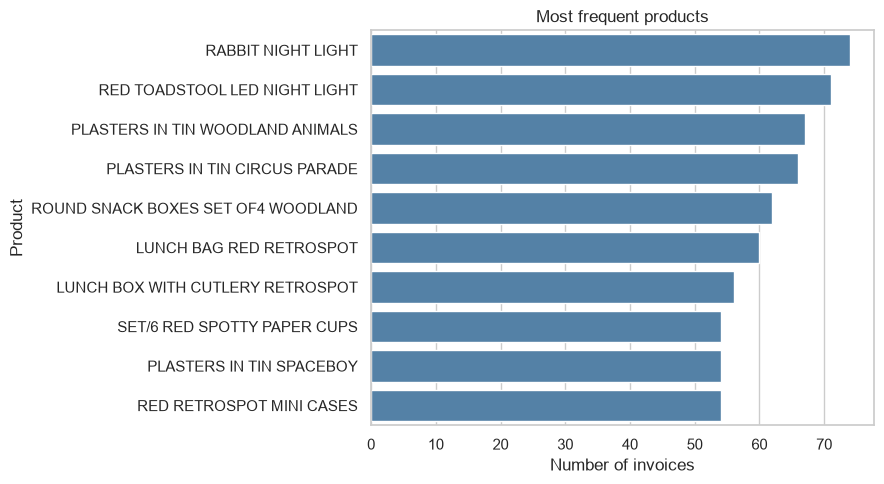

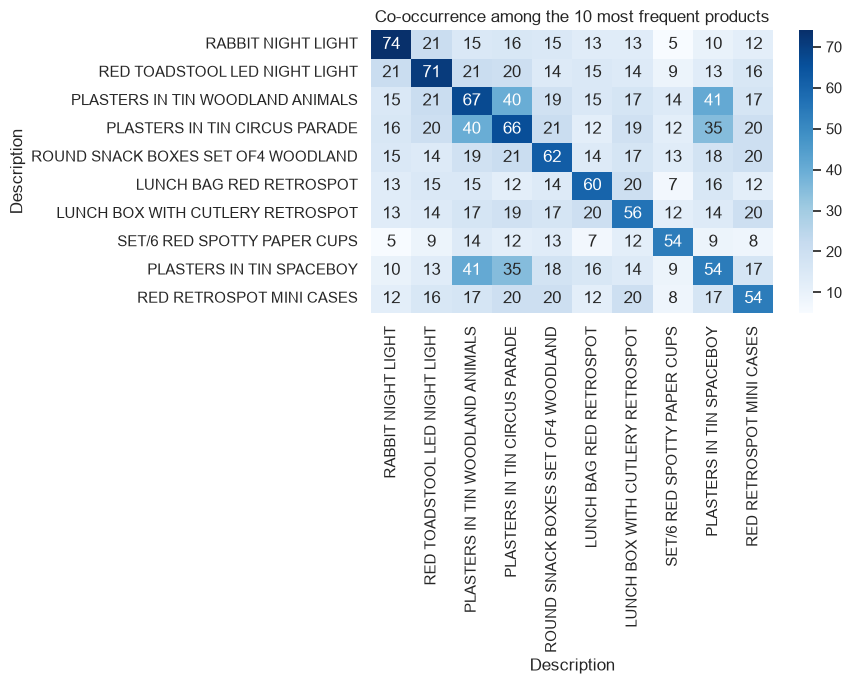

In [3]:
top_items = basket.sum().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_items.values, y=top_items.index, ax=ax, color="steelblue")
ax.set(xlabel="Number of invoices", ylabel="Product", title="Most frequent products")
plt.tight_layout()
plt.show()

# Co-occurrence counts show how often two of the popular products share an invoice.
cooccurrence = basket[top_items.index].astype(int).T.dot(basket[top_items.index].astype(int))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set(title="Co-occurrence among the 10 most frequent products")
plt.tight_layout()
plt.show()

## 2. Frequent itemsets with Apriori

Minimum support is **0.05**, or at least 20 of 387 invoices. This keeps frequent product combinations without treating one-off purchases as established patterns. An itemset's support is the share of invoices containing all its products.

In [4]:
MIN_SUPPORT = 0.05

def mine(method):
    timings = []
    for _ in range(5):
        start = perf_counter()
        result = method(basket, min_support=MIN_SUPPORT, use_colnames=True)
        timings.append(perf_counter() - start)
    return result, median(timings)

apriori_sets, apriori_seconds = mine(apriori)

def readable_itemsets(frame):
    table = frame.copy()
    table["itemset"] = table["itemsets"].map(lambda group: ", ".join(sorted(group)))
    table["size"] = table["itemsets"].map(len)
    return table[["itemset", "size", "support"]].sort_values(
        ["support", "itemset"], ascending=[False, True]
    ).reset_index(drop=True)

print(f"Apriori found {len(apriori_sets)} frequent itemsets in {apriori_seconds:.4f} seconds (median of 5 runs).")
display(readable_itemsets(apriori_sets).head(15))

Apriori found 113 frequent itemsets in 0.0112 seconds (median of 5 runs).


,itemset,size,support
0,RABBIT NIGHT LIGHT,1,0.191214
1,RED TOADSTOOL LED NIGHT LIGHT,1,0.183463
2,PLASTERS IN TIN WOODLAND ANIMALS,1,0.173127
3,PLASTERS IN TIN CIRCUS PARADE,1,0.170543
4,ROUND SNACK BOXES SET OF4 WOODLAND,1,0.160207
5,LUNCH BAG RED RETROSPOT,1,0.155039
6,LUNCH BOX WITH CUTLERY RETROSPOT,1,0.144703
7,PLASTERS IN TIN SPACEBOY,1,0.139535
8,RED RETROSPOT MINI CASES,1,0.139535
9,SET/6 RED SPOTTY PAPER CUPS,1,0.139535


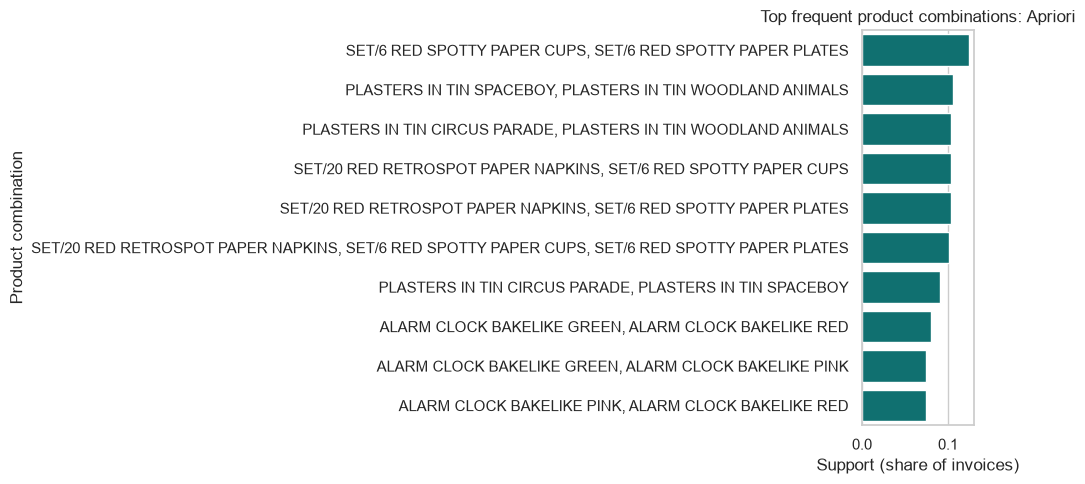

In [5]:
def plot_pairs(itemsets, title):
    pairs = readable_itemsets(itemsets).query("size >= 2").head(10)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=pairs, x="support", y="itemset", ax=ax, color="teal")
    ax.set(title=title, xlabel="Support (share of invoices)", ylabel="Product combination")
    plt.tight_layout()
    plt.show()

plot_pairs(apriori_sets, "Top frequent product combinations: Apriori")

## 3. Frequent itemsets with FP-Growth

The input baskets and 0.05 support threshold are exactly the same as for Apriori.

FP-Growth found 113 frequent itemsets in 0.0141 seconds (median of 5 runs).


,itemset,size,support
0,RABBIT NIGHT LIGHT,1,0.191214
1,RED TOADSTOOL LED NIGHT LIGHT,1,0.183463
2,PLASTERS IN TIN WOODLAND ANIMALS,1,0.173127
3,PLASTERS IN TIN CIRCUS PARADE,1,0.170543
4,ROUND SNACK BOXES SET OF4 WOODLAND,1,0.160207
5,LUNCH BAG RED RETROSPOT,1,0.155039
6,LUNCH BOX WITH CUTLERY RETROSPOT,1,0.144703
7,PLASTERS IN TIN SPACEBOY,1,0.139535
8,RED RETROSPOT MINI CASES,1,0.139535
9,SET/6 RED SPOTTY PAPER CUPS,1,0.139535


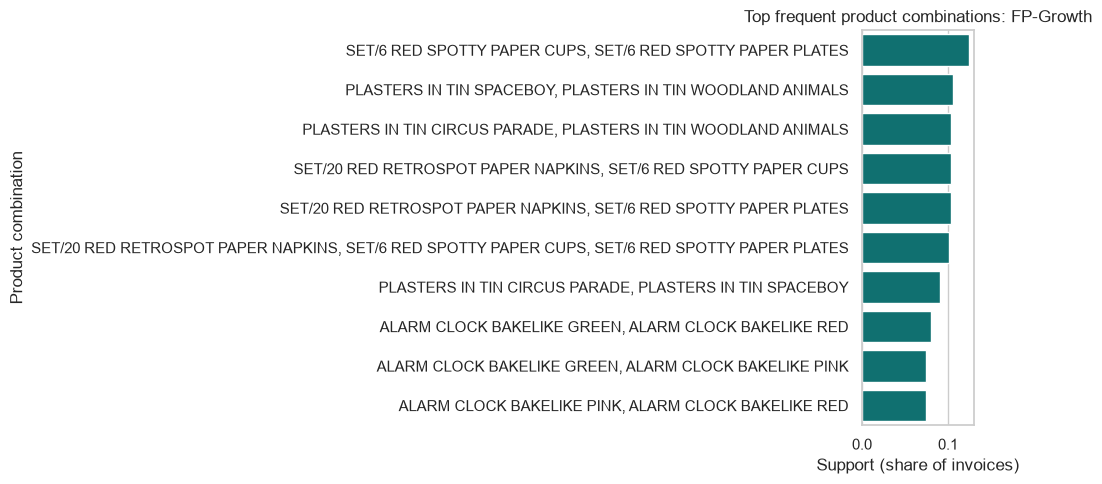

In [6]:
fp_sets, fp_seconds = mine(fpgrowth)
print(f"FP-Growth found {len(fp_sets)} frequent itemsets in {fp_seconds:.4f} seconds (median of 5 runs).")
display(readable_itemsets(fp_sets).head(15))
plot_pairs(fp_sets, "Top frequent product combinations: FP-Growth")

## 4. Association rules

Minimum confidence is **0.60**. A rule A → B means B appears in at least 60% of baskets containing A. Rule support is the share containing both A and B; lift greater than 1 means they co-occur more often than expected if independent.

In [7]:
MIN_CONFIDENCE = 0.60
apriori_rules = association_rules(apriori_sets, metric="confidence", min_threshold=MIN_CONFIDENCE)
fp_rules = association_rules(fp_sets, metric="confidence", min_threshold=MIN_CONFIDENCE)

def readable_rules(frame):
    table = frame.copy()
    table["antecedent"] = table["antecedents"].map(lambda group: ", ".join(sorted(group)))
    table["consequent"] = table["consequents"].map(lambda group: ", ".join(sorted(group)))
    return table[["antecedent", "consequent", "support", "confidence", "lift"]].sort_values(
        ["lift", "confidence", "antecedent", "consequent"],
        ascending=[False, False, True, True]
    ).reset_index(drop=True)

print(f"Apriori rules: {len(apriori_rules)}; FP-Growth rules: {len(fp_rules)}")
display(readable_rules(apriori_rules).head(12).round(3))
display(readable_rules(fp_rules).head(12).round(3))

Apriori rules: 38; FP-Growth rules: 38


,antecedent,consequent,support,confidence,lift
0,PACK OF 6 SKULL PAPER PLATES,PACK OF 6 SKULL PAPER CUPS,0.052,0.909,14.073
1,PACK OF 6 SKULL PAPER CUPS,PACK OF 6 SKULL PAPER PLATES,0.052,0.800,14.073
2,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.065,0.893,12.798
3,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.065,0.926,12.798
4,ALARM CLOCK BAKELIKE RED,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",0.065,0.676,9.017
5,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",ALARM CLOCK BAKELIKE RED,0.065,0.862,9.017
6,"ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIK...",ALARM CLOCK BAKELIKE GREEN,0.065,0.862,8.779
7,ALARM CLOCK BAKELIKE GREEN,"ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIK...",0.065,0.658,8.779
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.080,0.838,8.533
9,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.080,0.816,8.533


,antecedent,consequent,support,confidence,lift
0,PACK OF 6 SKULL PAPER PLATES,PACK OF 6 SKULL PAPER CUPS,0.052,0.909,14.073
1,PACK OF 6 SKULL PAPER CUPS,PACK OF 6 SKULL PAPER PLATES,0.052,0.800,14.073
2,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.065,0.893,12.798
3,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.065,0.926,12.798
4,ALARM CLOCK BAKELIKE RED,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",0.065,0.676,9.017
5,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",ALARM CLOCK BAKELIKE RED,0.065,0.862,9.017
6,"ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIK...",ALARM CLOCK BAKELIKE GREEN,0.065,0.862,8.779
7,ALARM CLOCK BAKELIKE GREEN,"ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIK...",0.065,0.658,8.779
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.080,0.838,8.533
9,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.080,0.816,8.533


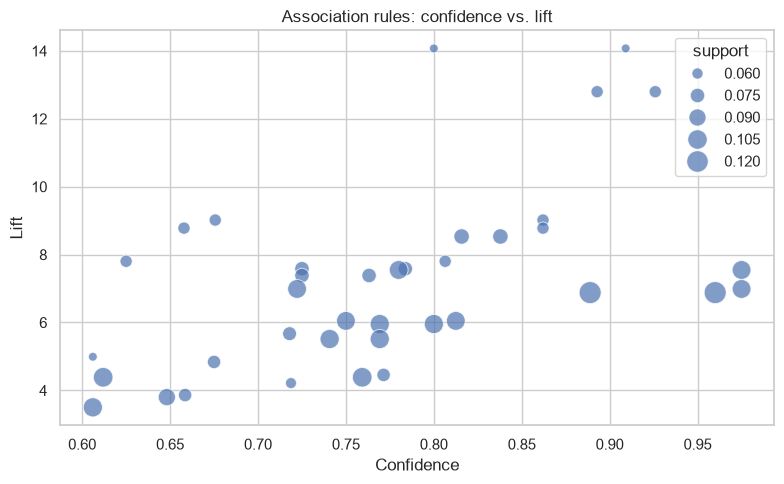

Example: PACK OF 6 SKULL PAPER PLATES → PACK OF 6 SKULL PAPER CUPS
Support: 5.2%; confidence: 90.9%; lift: 14.07
Interpretation: 90.9% of baskets with PACK OF 6 SKULL PAPER PLATES also contain PACK OF 6 SKULL PAPER CUPS. The products co-occur 14.07 times as often as expected from their separate frequencies. This is an association, not causation.


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=readable_rules(apriori_rules), x="confidence", y="lift",
                size="support", sizes=(40, 250), alpha=0.7, ax=ax)
ax.set(title="Association rules: confidence vs. lift", xlabel="Confidence", ylabel="Lift")
plt.tight_layout()
plt.show()

# Use a simple one-item-to-one-item rule to make the interpretation clear.
simple = readable_rules(apriori_rules)
simple = simple[~simple["antecedent"].str.contains(",") & ~simple["consequent"].str.contains(",")]
best = simple.iloc[0]
print(f"Example: {best['antecedent']} → {best['consequent']}")
print(f"Support: {best['support']:.1%}; confidence: {best['confidence']:.1%}; lift: {best['lift']:.2f}")
print(f"Interpretation: {best['confidence']:.1%} of baskets with {best['antecedent']} also contain "
      f"{best['consequent']}. The products co-occur {best['lift']:.2f} times as often "
      "as expected from their separate frequencies. This is an association, not causation.")

## 5. Comparative analysis

,algorithm,seconds,itemsets,rules
0,Apriori,0.0112,113,38
1,FP-Growth,0.0141,113,38


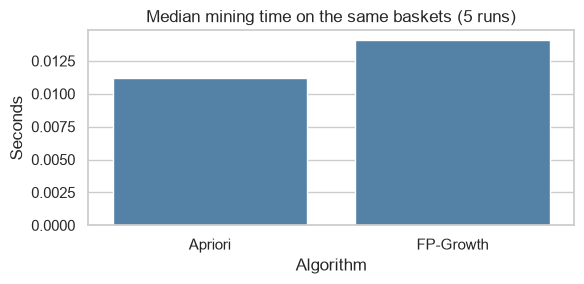

The frequent itemsets, support values, and rules match for both algorithms.
Apriori was faster by median time on this computer. Times can vary by computer and run.
Apriori generates candidates; FP-Growth builds an FP-tree to avoid that step. The FP-tree setup can outweigh its benefit on a small, sparse dataset.


In [9]:
a = readable_itemsets(apriori_sets).sort_values("itemset").reset_index(drop=True)
f = readable_itemsets(fp_sets).sort_values("itemset").reset_index(drop=True)
pd.testing.assert_frame_equal(a, f, check_exact=False, atol=1e-12)
ra = readable_rules(apriori_rules).sort_values(["antecedent", "consequent"]).reset_index(drop=True)
rf = readable_rules(fp_rules).sort_values(["antecedent", "consequent"]).reset_index(drop=True)
pd.testing.assert_frame_equal(ra, rf, check_exact=False, atol=1e-12)

comparison = pd.DataFrame({
    "algorithm": ["Apriori", "FP-Growth"],
    "seconds": [apriori_seconds, fp_seconds],
    "itemsets": [len(apriori_sets), len(fp_sets)],
    "rules": [len(apriori_rules), len(fp_rules)]
})
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(data=comparison, x="algorithm", y="seconds", ax=ax, color="steelblue")
ax.set(title="Median mining time on the same baskets (5 runs)", xlabel="Algorithm", ylabel="Seconds")
plt.tight_layout()
plt.show()

faster = comparison.loc[comparison["seconds"].idxmin(), "algorithm"]
print("The frequent itemsets, support values, and rules match for both algorithms.")
print(f"{faster} was faster by median time on this computer. Times can vary by computer and run.")
print("Apriori generates candidates; FP-Growth builds an FP-tree to avoid that step. "
      "The FP-tree setup can outweigh its benefit on a small, sparse dataset.")

**Challenge and decision.** The full dataset has many product names, and the delivery charge `POSTAGE` appears frequently. Using the France invoices and excluding postage kept the notebook practical and the associations product-focused. The same basket and threshold were used for both algorithms so their outputs can be compared fairly.

**Source:** Chen, D. (2015). *Online Retail* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33